In [ ]:
from __future__ import annotations

import gzip # Membaca file berformat gzip
import time # Mengukur durasi eksekusi model
from pathlib import Path # Manajemen path folder

import joblib # Menyimpan model ukuran besar
import matplotlib.pyplot as plt # Menyiapkan kanvas untuk membuat grafik
import numpy as np # Operasi matematika
import pandas as pd # Manipulasi tabel
import seaborn as sns # Menggambar grafiknya
from tqdm import tqdm # Menampilkan progress bar

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = Path('/content/drive/MyDrive/skripsi/data')
except ImportError:
    BASE_DIR = Path('./data')

Mounted at /content/drive


## KONFIGURASI INFERENCE


In [ ]:
# Menentukan model skenario yang dipake
NUM_CLASSES = 2
USE_SMOTE_MODEL = False

class_suffix = f'_{NUM_CLASSES}class'
smote_suffix = '_SMOTE' if USE_SMOTE_MODEL else '_NoSMOTE'
suffix = class_suffix + smote_suffix

WGS_FILE       = BASE_DIR / 'WGS_WestJava' / 'WGS_WestJava_227.vcf.gz'
DBNSFP_FILE    = BASE_DIR / 'dbNSFP' / 'dbNSFP5.3a_grch38.gz'
CLINVAR_FILE   = BASE_DIR / 'clinvar_dbnsfp_merged.csv'
MODEL_PATH     = BASE_DIR / f'ckpt_best_model{suffix}.joblib'
FINAL_OUTPUT   = BASE_DIR / 'WGS_JawaBarat_Clean_Predicted.csv'
CHECKPOINT_CSV = BASE_DIR / 'checkpoint_wgs_matches.csv'
CHECKPOINT_IDX = BASE_DIR / 'checkpoint_wgs_idx.txt'

LAMPIRAN_DIR   = BASE_DIR / 'Lampiran_Skripsi'
LAMPIRAN_DIR.mkdir(parents=True, exist_ok=True)

# Mengunci 7 fitur standar prediksi
FEATURE_COLS = ['CADD', 'SIFT', 'PolyPhen', 'MAF', 'REVEL', 'MetaSVM', 'PhyloP']

print('=' * 60)
print('TAHAP 5: INFERENCE SCREENING WGS JAWA BARAT')
print('=' * 60)

TAHAP 5: INFERENCE SCREENING WGS JAWA BARAT


## HELPER: Tabel box rapi (konsisten dengan pipeline 3 & 4)


In [ ]:
def print_box_table(df: pd.DataFrame, max_col_width: int = 20) -> None:
    cols = list(df.columns)
    widths = []
    for col in cols:
        max_data = df[col].astype(str).str.len().max() if len(df) > 0 else 0
        widths.append(min(max_col_width, max(len(str(col)), int(max_data), 3)))

    def fmt_row(cells):
        parts = [f' {str(c)[:widths[i]].ljust(widths[i])} ' for i, c in enumerate(cells)]
        return '│' + '│'.join(parts) + '│'

    def border(left, mid, right):
        return left + mid.join('─' * (w + 2) for w in widths) + right

    print(border('┌', '┬', '┐'))
    print(fmt_row(cols))
    print(border('├', '┼', '┤'))
    for _, row in df.iterrows():
        print(fmt_row(row.tolist()))
    print(border('└', '┴', '┘'))


def print_kv_table(data: dict, key_label: str = 'Item', val_label: str = 'Nilai') -> None:
    kw = max(len(key_label), max((len(str(k)) for k in data.keys()), default=0))
    vw = max(len(val_label), max((len(str(v)) for v in data.values()), default=0))

    def border(left, mid, right, fill):
        return left + fill * (kw + 2) + mid + fill * (vw + 2) + right

    print(border('┌', '┬', '┐', '─'))
    print(f'│ {key_label.ljust(kw)} │ {val_label.ljust(vw)} │')
    print(border('├', '┼', '┤', '─'))
    for k, v in data.items():
        print(f'│ {str(k).ljust(kw)} │ {str(v).ljust(vw)} │')
    print(border('└', '┴', '┘', '─'))

def extract_max_score(value: object) -> float:
    if pd.isna(value) or str(value).strip() in {'.', '', 'nan'}:
        return np.nan
    scores = []
    for item in str(value).split(';'):
        item = item.strip()
        if item and item != '.':
            try:
                scores.append(float(item))
            except ValueError:
                pass
    return max(scores) if scores else np.nan

## 1. CEK FILE INPUT


In [ ]:
for file_path in [WGS_FILE, DBNSFP_FILE, CLINVAR_FILE, MODEL_PATH]:
    if not file_path.exists():
        raise FileNotFoundError(f'File tidak ditemukan: {file_path}')
print('\n[INFO] Semua file input tersedia.')


[INFO] Semua file input tersedia.


## 2. MUAT MODEL DAN KONFIGURASI FITUR


In [ ]:
print('\nMemuat model Random Forest multiclass...')
# Memuat model yang telah dibuat
pipeline_data   = joblib.load(MODEL_PATH)
best_model      = pipeline_data['model']

# Mengambil Daftar Fitur yang Dipakai Model
model_features  = pipeline_data.get('selected_features',
                  pipeline_data.get('available_features', FEATURE_COLS))

# Mengambil Daftar Nama Kelas Penyakit
if 'label_encoder_classes' in pipeline_data:
    label_classes = list(pipeline_data['label_encoder_classes'])
elif NUM_CLASSES == 2:
    label_classes = ['Benign', 'Pathogenic']
else:
    label_classes = ['Benign', 'Likely benign', 'Likely pathogenic', 'Pathogenic']

# Menampilkan Tabel Ringkasan Info Model
print_kv_table({
    'Fitur Model'   : ', '.join(model_features),
    'Jumlah Fitur'  : str(len(model_features)),
    'Jumlah Kelas'  : str(len(label_classes)),
    'Kelas'         : ', '.join(label_classes),
}, key_label='Info Model', val_label='Nilai')


Memuat model Random Forest multiclass...
┌──────────────┬───────────────────────────────────────────────────┐
│ Info Model   │ Nilai                                             │
├──────────────┼───────────────────────────────────────────────────┤
│ Fitur Model  │ CADD, SIFT, PolyPhen, MAF, REVEL, MetaSVM, PhyloP │
│ Jumlah Fitur │ 7                                                 │
│ Jumlah Kelas │ 2                                                 │
│ Kelas        │ Benign, Pathogenic                                │
└──────────────┴───────────────────────────────────────────────────┘


## 3. EKSTRAK SNV DARI VCF

In [ ]:
print('\nMembaca dan mengekstrak varian SNV dari file VCF...')
start_time = time.time()
# Melewati Baris Header/Komentar VCF
n_skip = 0
with gzip.open(WGS_FILE, 'rt') as handle:
    for line in handle:
        if line.startswith('#'):
            n_skip += 1
        else:
            break
# Membaca Data VCF Secara Bertahap
vcf_reader = pd.read_csv(
    WGS_FILE, sep='\t', compression='gzip',
    skiprows=n_skip, header=None,
    usecols=[0, 1, 3, 4],
    names=['chr', 'pos', 'ref', 'alt'],
    dtype=str, chunksize=1_000_000,
)

snv_chunks = []
for chunk in tqdm(vcf_reader, desc='Membaca VCF', unit='chunk'):
  # Normalisasi Nama Kromosom & Filter Khusus Varian SNV
    chunk['chr'] = chunk['chr'].str.replace('chr', '', regex=False)
    mask = (
        (~chunk['alt'].str.contains(',', na=True)) &
        (chunk['ref'].str.len() == 1) &
        (chunk['alt'].str.len() == 1)
    )
    snv_chunks.append(chunk[mask][['chr', 'pos', 'ref', 'alt']])
# df_wgs = pd.concat(snv_chunks, ignore_index=True).drop_duplicates()
df_wgs = pd.concat(snv_chunks, ignore_index=True).drop_duplicates()
elapsed_vcf = (time.time() - start_time) / 60
print(f'\n[SELESAI] Berhasil mengekstrak {len(df_wgs):,} mutasi SNV unik dari WGS.')

print_kv_table({
    'Total SNV unik': f'{len(df_wgs):,}',
    'Waktu baca VCF': f'{elapsed_vcf:.1f} menit',
}, key_label='Info', val_label='Nilai')

print('\n20 SNV Pertama dari VCF:')
print_box_table(df_wgs.head(20))



Membaca dan mengekstrak varian SNV dari file VCF...


Membaca VCF: 15chunk [04:40, 18.67s/chunk]



[SELESAI] Berhasil mengekstrak 14,528,380 mutasi SNV unik dari WGS.
┌────────────────┬────────────┐
│ Info           │ Nilai      │
├────────────────┼────────────┤
│ Total SNV unik │ 14,528,380 │
│ Waktu baca VCF │ 5.0 menit  │
└────────────────┴────────────┘

20 SNV Pertama dari VCF:
┌─────┬───────┬─────┬─────┐
│ chr │ pos   │ ref │ alt │
├─────┼───────┼─────┼─────┤
│ 1   │ 10177 │ A   │ C   │
│ 1   │ 10492 │ C   │ T   │
│ 1   │ 13273 │ G   │ C   │
│ 1   │ 14462 │ A   │ G   │
│ 1   │ 15484 │ G   │ A   │
│ 1   │ 17005 │ A   │ G   │
│ 1   │ 17020 │ G   │ A   │
│ 1   │ 17257 │ G   │ A   │
│ 1   │ 46633 │ T   │ A   │
│ 1   │ 47267 │ T   │ G   │
│ 1   │ 49157 │ G   │ A   │
│ 1   │ 49298 │ T   │ C   │
│ 1   │ 49554 │ A   │ G   │
│ 1   │ 51479 │ T   │ A   │
│ 1   │ 51979 │ G   │ T   │
│ 1   │ 52238 │ T   │ G   │
│ 1   │ 54050 │ A   │ G   │
│ 1   │ 54353 │ C   │ A   │
│ 1   │ 54490 │ G   │ A   │
│ 1   │ 54591 │ A   │ G   │
└─────┴───────┴─────┴─────┘


## 4. ANOTASI DENGAN dbNSFP + CHECKPOINT


In [ ]:
print('\nMulai mencari nilai fitur ke database dbNSFP...')
print('Sistem checkpoint aktif: progress disimpan berkala setiap 10 chunk.')

print('\nMendeteksi kolom dbNSFP...')
_header = pd.read_csv(DBNSFP_FILE, sep='\t', compression='gzip', nrows=0)
_all_cols = _header.columns.tolist()
# Deteksi & Pemetaan 12 Kolom dbNSFP secara pintar
def _find_col(keywords: list) -> str | None:
    for col in _all_cols:
        if any(kw.lower() in col.lower() for kw in keywords):
            return col
    return None

_col_chr      = '#chr'         if '#chr'         in _all_cols else _find_col(['hg38_chr', 'chr'])
_col_pos      = 'pos(1-based)' if 'pos(1-based)' in _all_cols else _find_col(['hg38_pos', 'pos'])
_col_cadd     = _find_col(['CADD_phred'])
_col_sift     = _find_col(['SIFT_score'])
_col_polyphen = _find_col(['Polyphen2_HVAR_score', 'Polyphen2_HDIV_score'])
_col_maf      = _find_col(['1000Gp3_AF'])
_col_revel    = _find_col(['REVEL_score'])
_col_metasvm  = _find_col(['MetaSVM_score'])
_col_phylop   = _find_col(['PhyloP100way_vertebrate', 'phyloP100way_vertebrate'])
_col_gene     = _find_col(['genename', 'Gene_name'])

_FALLBACKS = {
    '_col_chr': '#chr', '_col_pos': 'pos(1-based)',
    '_col_cadd': 'CADD_phred', '_col_sift': 'SIFT_score',
    '_col_polyphen': 'Polyphen2_HVAR_score', '_col_maf': '1000Gp3_AF',
    '_col_revel': 'REVEL_score', '_col_metasvm': 'MetaSVM_score',
    '_col_phylop': 'PhyloP100way_vertebrate',
    '_col_gene': 'genename',
}
for _var, _val in [('_col_chr', _col_chr), ('_col_pos', _col_pos),
                   ('_col_cadd', _col_cadd), ('_col_sift', _col_sift),
                   ('_col_polyphen', _col_polyphen), ('_col_maf', _col_maf),
                   ('_col_revel', _col_revel), ('_col_metasvm', _col_metasvm),
                   ('_col_phylop', _col_phylop), ('_col_gene', _col_gene)]:
    if _val is None:
        print(f'  [PERINGATAN] {_var} tidak ditemukan, fallback ke: {_FALLBACKS[_var]}')

_col_chr      = _col_chr      or _FALLBACKS['_col_chr']
_col_pos      = _col_pos      or _FALLBACKS['_col_pos']
_col_cadd     = _col_cadd     or _FALLBACKS['_col_cadd']
_col_sift     = _col_sift     or _FALLBACKS['_col_sift']
_col_polyphen = _col_polyphen or _FALLBACKS['_col_polyphen']
_col_maf      = _col_maf      or _FALLBACKS['_col_maf']
_col_revel    = _col_revel    or _FALLBACKS['_col_revel']
_col_metasvm  = _col_metasvm  or _FALLBACKS['_col_metasvm']
_col_phylop   = _col_phylop   or _FALLBACKS['_col_phylop']
_col_gene     = _col_gene     or _FALLBACKS['_col_gene']

DBNSFP_COLS_MAP = {
    _col_chr      : 'chr',
    _col_pos      : 'pos',
    'ref'         : 'ref',
    'alt'         : 'alt',
    _col_gene     : 'Gene',
    _col_cadd     : 'CADD',
    _col_sift     : 'SIFT',
    _col_polyphen : 'PolyPhen',
    _col_maf      : 'MAF',
    _col_revel    : 'REVEL',
    _col_metasvm  : 'MetaSVM',
    _col_phylop   : 'PhyloP',
}

DBNSFP_COLS_MAP = {k: v for k, v in DBNSFP_COLS_MAP.items() if k is not None and k != v}

dbnsfp_cols_needed_raw = [
    _col_chr, _col_pos, 'ref', 'alt', _col_gene,
    _col_cadd, _col_sift, _col_polyphen, _col_maf,
    _col_revel, _col_metasvm, _col_phylop
]

dbnsfp_cols_needed = list(dict.fromkeys(c for c in dbnsfp_cols_needed_raw if c is not None))

print('\nKolom yang akan dibaca (usecols) dari dbNSFP:')
print(dbnsfp_cols_needed)

print('\nKolom yang akan di-rename menjadi standar pipeline:')
print_kv_table(
    DBNSFP_COLS_MAP,
    key_label='Nama Asli', val_label='Menjadi'
)

chunk_size      = 500_000
save_every      = 10
matched_chunks: list[pd.DataFrame] = []
start_chunk_idx = 0

# Sistem Auto-Resume Checkpoint
if CHECKPOINT_CSV.exists() and CHECKPOINT_IDX.exists():
    with open(CHECKPOINT_IDX, 'r', encoding='utf-8') as f:
        start_chunk_idx = int(f.read().strip())
    print(f'Resume terdeteksi dari chunk ke-{start_chunk_idx}.')
    matched_chunks.append(pd.read_csv(CHECKPOINT_CSV, dtype=str))
else:
    print('Memulai anotasi dari awal (tidak ada checkpoint).')

reader = pd.read_csv(
    DBNSFP_FILE, sep='\t', compression='gzip',
    chunksize=chunk_size, usecols=dbnsfp_cols_needed, dtype=str,
)
# Pencarian Bertahap (Chunking) & Inner Join
start_time = time.time()
for chunk_index, chunk in enumerate(tqdm(reader, desc='Mencari di dbNSFP')):
    if chunk_index < start_chunk_idx:
        continue

    chunk = chunk.rename(columns=DBNSFP_COLS_MAP)
    chunk['chr'] = chunk['chr'].astype(str)
    chunk['pos'] = chunk['pos'].astype(str)

    for feat in FEATURE_COLS:
        if feat in chunk.columns:
            chunk[feat] = chunk[feat].apply(extract_max_score)

    matched = pd.merge(df_wgs, chunk, on=['chr', 'pos', 'ref', 'alt'], how='inner')
    if not matched.empty:
        matched_chunks.append(matched)

    if (chunk_index + 1) % save_every == 0 and matched_chunks:
        checkpoint_df = pd.concat(matched_chunks, ignore_index=True).drop_duplicates()
        checkpoint_df.to_csv(CHECKPOINT_CSV, index=False)
        with open(CHECKPOINT_IDX, 'w', encoding='utf-8') as f:
            f.write(str(chunk_index + 1))
        tqdm.write(f'Checkpoint disimpan di chunk {chunk_index + 1} | match: {len(checkpoint_df):,}')

if not matched_chunks:
    raise ValueError('Tidak ada mutasi yang cocok dengan dbNSFP!')
# Penggabungan Akhir & Penghapusan File Sementara
df_final = pd.concat(matched_chunks, ignore_index=True).drop_duplicates()
for temp_path in [CHECKPOINT_CSV, CHECKPOINT_IDX]:
    if temp_path.exists():
        temp_path.unlink()

print(f'\n[SELESAI] Berhasil menemukan {len(df_final):,} mutasi pasien di dalam dbNSFP.')


Mulai mencari nilai fitur ke database dbNSFP...
Sistem checkpoint aktif: progress disimpan berkala setiap 10 chunk.

Mendeteksi kolom dbNSFP...

Kolom yang akan dibaca (usecols) dari dbNSFP:
['#chr', 'pos(1-based)', 'ref', 'alt', 'genename', 'CADD_phred', 'SIFT_score', 'Polyphen2_HDIV_score', '1000Gp3_AF', 'REVEL_score', 'MetaSVM_score', 'phyloP100way_vertebrate']

Kolom yang akan di-rename menjadi standar pipeline:
┌─────────────────────────┬──────────┐
│ Nama Asli               │ Menjadi  │
├─────────────────────────┼──────────┤
│ #chr                    │ chr      │
│ pos(1-based)            │ pos      │
│ genename                │ Gene     │
│ CADD_phred              │ CADD     │
│ SIFT_score              │ SIFT     │
│ Polyphen2_HDIV_score    │ PolyPhen │
│ 1000Gp3_AF              │ MAF      │
│ REVEL_score             │ REVEL    │
│ MetaSVM_score           │ MetaSVM  │
│ phyloP100way_vertebrate │ PhyloP   │
└─────────────────────────┴──────────┘
Resume terdeteksi dari chunk ke-1

Mencari di dbNSFP: 140it [1:12:34, 54.47s/it]

Checkpoint disimpan di chunk 140 | match: 27,771


Mencari di dbNSFP: 150it [1:22:01, 56.47s/it]

Checkpoint disimpan di chunk 150 | match: 29,905


Mencari di dbNSFP: 160it [1:31:21, 56.70s/it]

Checkpoint disimpan di chunk 160 | match: 32,227


Mencari di dbNSFP: 170it [1:40:42, 55.89s/it]

Checkpoint disimpan di chunk 170 | match: 33,522


Mencari di dbNSFP: 173it [1:43:10, 35.79s/it]



[SELESAI] Berhasil menemukan 33,522 mutasi pasien di dalam dbNSFP.


## 5. PEMBERSIHAN FITUR


In [ ]:
print('\nMembersihkan dan memvalidasi fitur...')
# Memastikan semua fitur berupa angka
for col in model_features:
    if col in df_final.columns:
        df_final[col] = pd.to_numeric(df_final[col], errors='coerce')
    else:
        print(f'  [PERINGATAN] Fitur "{col}" tidak ada di hasil anotasi, diisi NaN.')
        df_final[col] = np.nan

if 'MAF' in df_final.columns:
    before = len(df_final)
    # Membuang mutasi yang umum di populasi
    df_final['_maf_filter'] = df_final['MAF'].fillna(0)
    df_final = df_final[df_final['_maf_filter'] <= 0.01].drop(columns=['_maf_filter'])
    after = len(df_final)
    print(f'  Filter MAF ≤ 1%      : {before:,} → {after:,} mutasi ({before - after:,} dibuang)')

print('\nMemfilter Varian yang Sudah Ada di ClinVar (Mencari Novel Variants)...')
df_clinvar = pd.read_csv(CLINVAR_FILE, usecols=['chr', 'pos', 'ref', 'alt'], dtype=str)
df_clinvar['chr'] = df_clinvar['chr'].astype(str).str.replace('chr', '', regex=False)

before_clinvar = len(df_final)
# Membuang mutasi yang sudah ada di clinvar
df_final = df_final.merge(df_clinvar, on=['chr', 'pos', 'ref', 'alt'], how='left', indicator=True)
df_final = df_final[df_final['_merge'] == 'left_only'].drop(columns=['_merge'])
after_clinvar = len(df_final)
print(f'  Filter ClinVar Novelty: {before_clinvar:,} → {after_clinvar:,} mutasi ({(before_clinvar - after_clinvar):,} dibuang karena sudah diketahui)')

print_kv_table({
    'Mutasi setelah filter': f'{len(df_final):,}',
    'Fitur tersedia'       : ', '.join([f for f in model_features if f in df_final.columns]),
}, key_label='Info', val_label='Nilai')


Membersihkan dan memvalidasi fitur...
  Filter MAF ≤ 1%      : 33,522 → 33,282 mutasi (240 dibuang)

Memfilter Varian yang Sudah Ada di ClinVar (Mencari Novel Variants)...
  Filter ClinVar Novelty: 33,282 → 33,015 mutasi (267 dibuang karena sudah diketahui)
┌───────────────────────┬───────────────────────────────────────────────────┐
│ Info                  │ Nilai                                             │
├───────────────────────┼───────────────────────────────────────────────────┤
│ Mutasi setelah filter │ 33,015                                            │
│ Fitur tersedia        │ CADD, SIFT, PolyPhen, MAF, REVEL, MetaSVM, PhyloP │
└───────────────────────┴───────────────────────────────────────────────────┘


## 6. INFERENSI


In [ ]:
print('\nModel sedang mengevaluasi probabilitas tiap kelas...')
# Menghitung Persentase Peluang Tiap Kelas
probabilities   = best_model.predict_proba(df_final[model_features])
predicted_index = np.argmax(probabilities, axis=1)
predicted_label = [label_classes[i] for i in predicted_index]
# Menyimpan Persentase Peluang ke Kolom Tabel
for class_index, class_name in enumerate(label_classes):
    col_name = f'Prob_{class_name.replace(" ", "_").lower()}'
    df_final[col_name] = (probabilities[:, class_index] * 100).round(2)

df_final['Predicted_Class'] = predicted_label
# Menghitung Skor Risiko Gabungan
prob_path   = df_final.get('Prob_pathogenic', pd.Series(0, index=df_final.index))
prob_likely = df_final.get('Prob_likely_pathogenic', pd.Series(0, index=df_final.index))
# Mengurutkan / Memprioritaskan Varian
df_final['Risk_Score'] = (prob_path + prob_likely).round(2)
df_final = df_final.sort_values('Risk_Score', ascending=False)


Model sedang mengevaluasi probabilitas tiap kelas...


## 7. SIMPAN DAN TAMPILKAN HASIL


In [ ]:
# Menentukan Kolom Utama di Bagian Paling Kiri
output_columns = ['chr', 'pos', 'Gene', 'ref', 'alt', 'Predicted_Class', 'Risk_Score']
# Pengaman Jika Kolom Gene Tidak Ada
if 'Gene' not in df_final.columns:
    output_columns.remove('Gene')
# Menambahkan Rincian Probabilitas dan 7 Skor Fitur di Belakangnya
output_columns += [c for c in df_final.columns if c.startswith('Prob_')]
output_columns += [f for f in model_features if f in df_final.columns]
output_columns  = list(dict.fromkeys(output_columns))

df_export = df_final[output_columns].copy()

In [ ]:
# Menyimpan Tabel Gabungan Utuh
df_export.to_csv(FINAL_OUTPUT, index=False)
print(f'\n[LAMPIRAN] Tabel Inferensi Penuh ({len(df_export):,} varian, sudah bersih + prediksi):')
print(f'   -> {FINAL_OUTPUT}')

print('\nMemecah file hasil prediksi per kelas...')
# Memecah File Berdasarkan Kelas Prediksi
for class_name in df_export['Predicted_Class'].unique():
    clean_name = class_name.replace(' ', '_')
    class_df = df_export[df_export['Predicted_Class'] == class_name]
    class_file_path = BASE_DIR / f'WGS_{clean_name}.csv'
    class_df.to_csv(class_file_path, index=False)
    print(f'   - {class_name.ljust(18)} : {len(class_df):,} baris -> WGS_{clean_name}.csv')


[LAMPIRAN] Tabel Inferensi Penuh (33,015 varian, sudah bersih + prediksi):
   -> /content/drive/MyDrive/skripsi/data/WGS_JawaBarat_Clean_Predicted.csv

Memecah file hasil prediksi per kelas...
   - Pathogenic         : 9,942 baris -> WGS_Pathogenic.csv
   - Benign             : 23,073 baris -> WGS_Benign.csv


In [ ]:
# Menentukan Lokasi & Nama File
all_patho_path = LAMPIRAN_DIR / 'Lampiran_Semua_Pathogenic_WGS.csv'
# Menyaring Khusus Varian Pathogenic
df_all_pathogenic = df_export[df_export['Predicted_Class'] == 'Pathogenic'].copy()
# Menyimpan ke CSV & Mencetak Informasi
df_all_pathogenic.to_csv(all_patho_path, index=False)
print(f'\n[LAMPIRAN] Seluruh Varian Patogenik ({len(df_all_pathogenic):,} baris) tersimpan di:')
print(f'   -> {all_patho_path}')


[LAMPIRAN] Seluruh Varian Patogenik (9,942 baris) tersimpan di:
   -> /content/drive/MyDrive/skripsi/data/Lampiran_Skripsi/Lampiran_Semua_Pathogenic_WGS.csv


In [ ]:
# Menyimpan File CSV untuk Tabel Laporan / Lampiran
appendix_path = LAMPIRAN_DIR / 'Lampiran_Top20_Pathogenic.csv'
df_all_pathogenic.head(20).to_csv(appendix_path, index=False)
print(f'\n[LAMPIRAN] Top 20 Pathogenic (untuk copy-paste ke Tabel 4.6 Word):')
print(f'   -> {appendix_path}')
print('   (Buka file ini di Excel, lalu copy-paste langsung ke Microsoft Word)')

print('\n20 Varian Prioritas Tertinggi (Preview di Terminal):')
# Menampilkan Preview 20 Varian Teratas di Terminal
preview_cols = ['chr', 'pos', 'Gene', 'ref', 'alt', 'Predicted_Class', 'Risk_Score']
if 'Gene' not in df_final.columns:
    preview_cols.remove('Gene')
preview_cols += [f for f in model_features if f in df_final.columns][:4]
print_box_table(df_export[preview_cols].head(20).reset_index(drop=True))

print('\n+-- DISTRIBUSI PREDIKSI KELAS --')
# Menghitung dan Menampilkan Distribusi Kelas Prediksi
dist = df_final['Predicted_Class'].value_counts()
print_kv_table({k: f'{v:,} ({v/len(df_final)*100:.1f}%)' for k, v in dist.items()},
               key_label='Kelas', val_label='Jumlah')


[LAMPIRAN] Top 20 Pathogenic (untuk copy-paste ke Tabel 4.6 Word):
   -> /content/drive/MyDrive/skripsi/data/Lampiran_Skripsi/Lampiran_Top20_Pathogenic.csv
   (Buka file ini di Excel, lalu copy-paste langsung ke Microsoft Word)

20 Varian Prioritas Tertinggi (Preview di Terminal):
┌─────┬───────────┬──────────────────────┬─────┬─────┬─────────────────┬────────────┬──────┬───────┬──────────┬─────┐
│ chr │ pos       │ Gene                 │ ref │ alt │ Predicted_Class │ Risk_Score │ CADD │ SIFT  │ PolyPhen │ MAF │
├─────┼───────────┼──────────────────────┼─────┼─────┼─────────────────┼────────────┼──────┼───────┼──────────┼─────┤
│ 7   │ 94410457  │ COL1A2;COL1A2;COL1A2 │ G   │ A   │ Pathogenic      │ 99.94      │ 27.2 │ 0.0   │ 1.0      │ nan │
│ 1   │ 40303627  │ COL9A2;COL9A2;COL9A2 │ C   │ T   │ Pathogenic      │ 99.91      │ 28.4 │ 0.0   │ 1.0      │ nan │
│ 19  │ 8073093   │ FBN3;FBN3;FBN3;FBN3; │ C   │ T   │ Pathogenic      │ 99.91      │ 27.2 │ 0.0   │ 0.998    │ nan │
│ 2   │ 1

## 8. VISUALISASI



Membuat visualisasi hasil inference...
Melakukan perhitungan Principal Component Analysis (PCA)...

Visualisasi WGS disimpan di: /content/drive/MyDrive/skripsi/data/Lampiran_Skripsi/wgs_inference_visualization.png


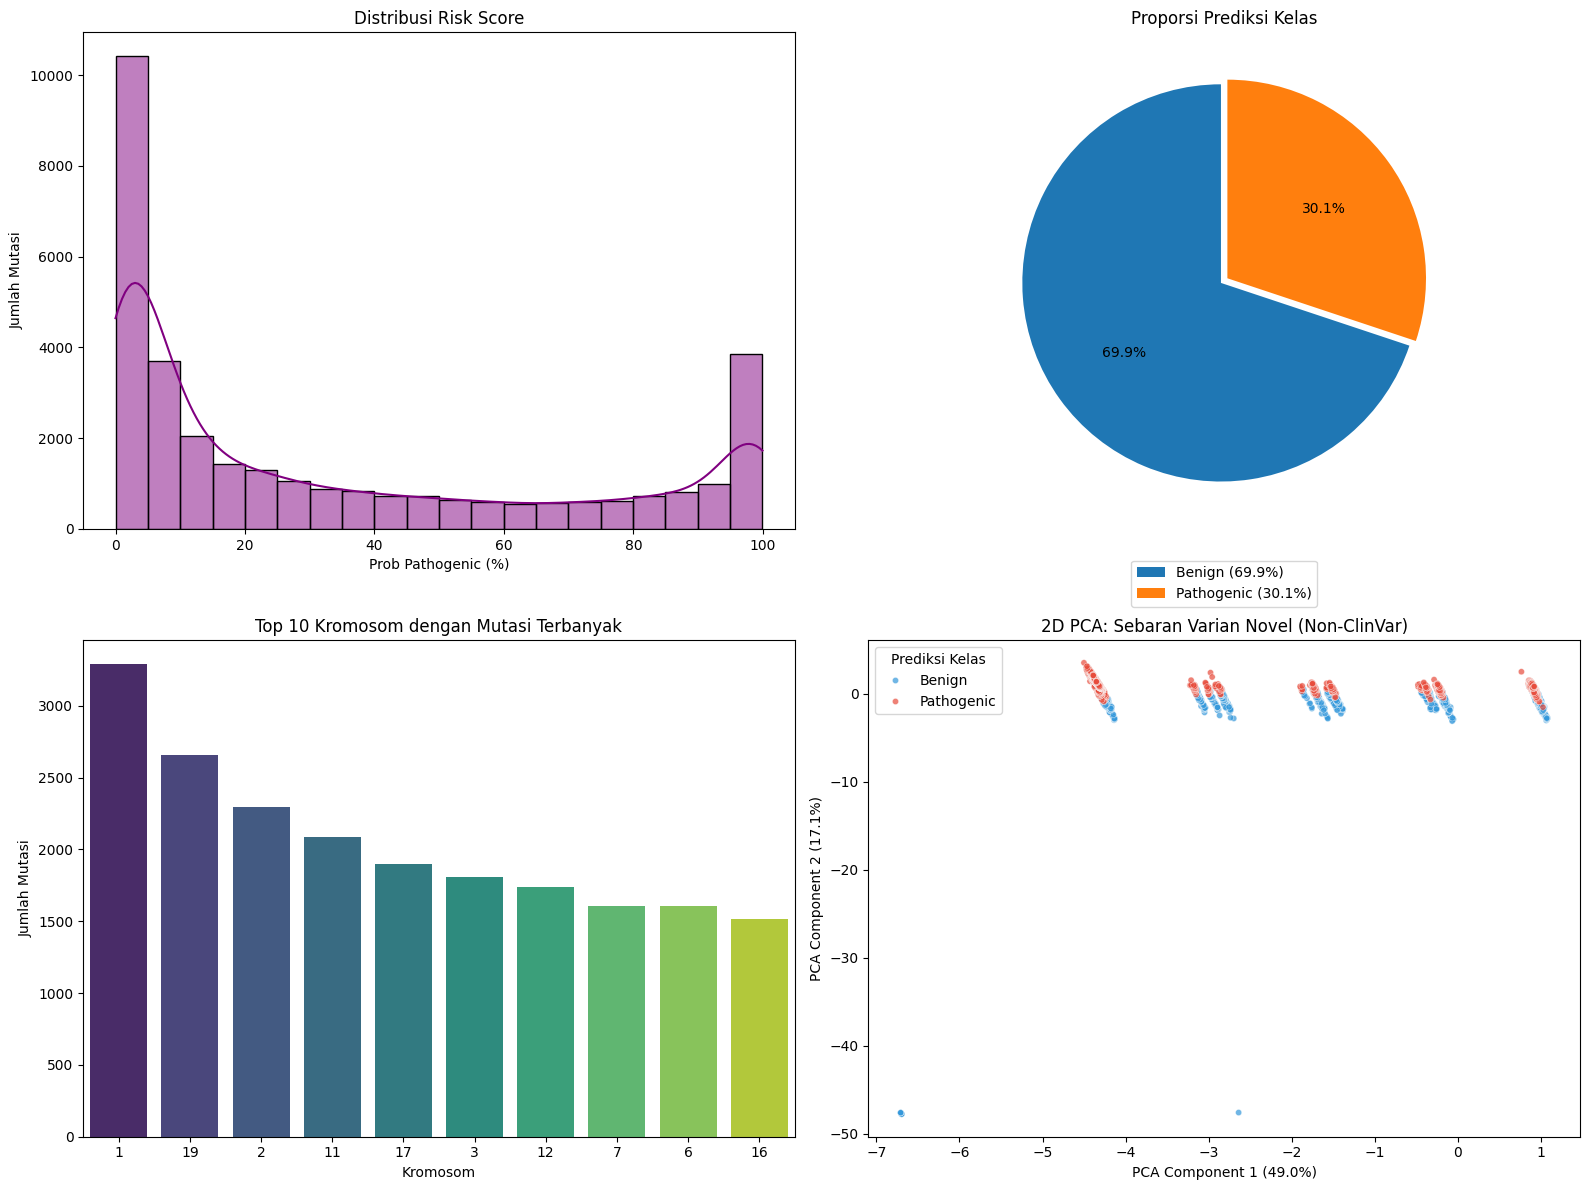


TAHAP 5 SELESAI!


In [ ]:
print('\nMembuat visualisasi hasil inference...')
# Persiapan Kanvas Gambar (3 Grafik Evaluasi Hasil Inferensi)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Grafik 1: Histogram Distribusi Risk Score
sns.histplot(data=df_final, x='Risk_Score', bins=20, kde=True, color='purple', ax=axes[0])
axes[0].set_title('Distribusi Risk Score', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Prob Pathogenic (%)' if NUM_CLASSES == 2 else 'Prob Pathogenic + Likely pathogenic (%)', fontsize=10)
axes[0].set_ylabel('Jumlah Mutasi', fontsize=10)

# Grafik 2: Pie Chart Proporsi Prediksi Kelas
counts = df_final['Predicted_Class'].value_counts()
def fmt(pct):
    return f'{pct:.1f}%' if pct >= 10 else ''

wedges, texts, autotexts = axes[1].pie(
    counts,
    startangle=90,
    explode=[0.02] * len(counts),
    autopct=fmt,
    textprops={'fontsize': 10}
)
labels_with_pct = [f'{idx} ({val/counts.sum()*100:.1f}%)' for idx, val in zip(counts.index, counts)]
axes[1].legend(wedges, labels_with_pct, loc='upper center', bbox_to_anchor=(0.5, -0.05), ncol=1)
axes[1].set_title('Proporsi Prediksi Kelas', fontsize=12, fontweight='bold')

# Grafik 3: Bar Chart Top 10 Kromosom
top_chr = df_final['chr'].value_counts().head(10)
sns.barplot(x=top_chr.index, y=top_chr.values, hue=top_chr.index, palette='viridis', legend=False, ax=axes[2])
axes[2].set_title('Top 10 Kromosom dengan Mutasi Terbanyak', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Kromosom', fontsize=10)
axes[2].set_ylabel('Jumlah Mutasi', fontsize=10)

plt.tight_layout()
# Penyimpanan Gambar Resolusi Tinggi
vis_path = LAMPIRAN_DIR / 'wgs_inference_visualization.png'
plt.savefig(vis_path, dpi=300, bbox_inches='tight')
print(f'\nVisualisasi WGS disimpan di: {vis_path}')

plt.show()

print('\nTAHAP 5 SELESAI!')
print('Catatan: Untuk analisis visualisasi spasial PCA terpadu, silakan jalankan 06_pca_analysis.ipynb')


> **Catatan Analisis Visualisasi Lanjutan:**
> Proyeksi spasial varian novel (WGS Jawa Barat) ke dalam ruang koordinat referensi ClinVar menggunakan Principal Component Analysis (PCA) terpadu disajikan secara lengkap pada notebook **`06_pca_analysis.ipynb`**.
